# 03 · What drives the choice within a search

Notebook 02 measured how much position matters. This notebook asks what else drives which
hotel gets chosen — price, promotions, stars, reviews, location — and puts every effect on a
common scale: **dollars of price cut**. "Moving a hotel from position 10 to position 1 is
worth the same to a searcher as cutting its price by $X."

**Model.** A conditional logit on the randomly ordered searches. Each search with exactly one
chosen hotel is one observation; the probability that hotel *i* is chosen is
exp(u_i) / Σ_j exp(u_j) over the hotels shown, with u_i = position effect + attributes · β.
Everything common to the search (destination, dates, how keen this user was to click at all)
cancels out of that ratio. That fits a release that contains only searches with a click: the
model conditions on exactly that.

**Why the random arm.** Position there is (nearly) unrelated to the hotel, so position and
attribute effects can be separated. Price was *not* randomized anywhere, so the price
coefficient is an observational estimate; section 3 is about making it as clean as the data
allows.

In [1]:
import sys
from pathlib import Path


def _project_root() -> Path:
    """The folder holding src/hotelrank, wherever the script or notebook was started."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "hotelrank" / "__init__.py").exists():
            return p
    for marker in here.glob("*/src/hotelrank/__init__.py"):
        return marker.parents[2]
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hotelrank import audit, choice, position
from hotelrank.data import FIGURES_DIR, ROOT as PROJECT_ROOT, load
from hotelrank.records import write_metrics

COLUMNS = ["srch_id", "position", "random_bool", "click_bool", "booking_bool", "price_usd", "prop_starrating",
           "prop_review_score", "prop_brand_bool", "prop_location_score1", "promotion_flag", "prop_id"]
df, SOURCE = load(COLUMNS)
flags_path = PROJECT_ROOT / "data" / "interim" / "search_flags.parquet"
if SOURCE == "real" and flags_path.exists():
    flags = pd.read_parquet(flags_path)
else:
    flags = audit.price_flags(df, audit.per_search(df)).reset_index().rename(columns={"index": "srch_id"})
x = position.analysis_sample(df, flags)
del df
# Hotel average price over all its impressions (both arms), then keep the random arm.
x = choice.add_hotel_mean_price(x[x["random_bool"].astype(bool)], full=x)
x["upscale"] = (x["prop_starrating"] >= 4).astype(np.float32)
x["log_price_x_upscale"] = x["log_price"] * x["upscale"]
x["hotel_mean_x_upscale"] = x["hotel_mean_log_price"] * x["upscale"]
MEDIAN_PRICE = float(x["price_usd"].median())
print(SOURCE, f"{len(x):,} random-arm impressions, median price ${MEDIAN_PRICE:.0f}")

real 2,767,426 random-arm impressions, median price $129


## 1. The main model: clicks

Searches with exactly one click (93% of random-arm searches). Position enters as one
coefficient per slot (position 1 is the reference). Attributes: log price, the hotel's own
average log price (section 3), stars, review score (0 if none) with a no-reviews flag, brand,
location score, promotion flag.

In [2]:
data = {"click": choice.build(x, "click_bool"), "booking": choice.build(x, "booking_bool")}
fits = {k: choice.fit(d) for k, d in data.items()}
main = fits["click"]
print({k: d.meta for k, d in data.items()}, {k: f.converged for k, f in fits.items()})
main.table().loc[choice.ATTRIBUTES].round(4)

{'click': {'rows': 2569365, 'searches': 106614}, 'booking': {'rows': 357965, 'searches': 15203}} {'click': True, 'booking': True}


,beta,se
log_price,-1.7473,0.0173
hotel_mean_log_price,1.3762,0.0199
prop_starrating,0.2834,0.0053
prop_review_score,0.1362,0.0064
no_reviews,0.1556,0.0301
prop_brand_bool,0.0841,0.0082
prop_location_score1,0.0866,0.0035
promotion_flag,0.2808,0.0083


**Reading the coefficients.** Utility is on a log-odds scale. The log-price coefficient is a
semi-elasticity: because any single hotel's chance of being chosen is small, it is close to
the own-price elasticity of being clicked. A hotel 10% dearer than usual is clicked about
1 − 1.1^β ≈ 15% less often.

**Consistency with notebook 02.** In this model, the same hotel shown at position 1 rather
than position 30 has its choice odds multiplied by exp(−β_pos30). Notebook 02 measured the
click ratio between those positions directly (4.4× adjusted, 4.9× raw).

In [3]:
pos30_ratio = float(np.exp(-main.coef("pos_30")))
elasticity = {k: round(f.coef("log_price"), 3) for k, f in fits.items()}
print(f"implied position-1 vs position-30 odds ratio: {pos30_ratio:.2f}; price coefficient {elasticity}")

implied position-1 vs position-30 odds ratio: 4.93; price coefficient {'click': -1.747, 'booking': -2.636}


## 2. Every effect in dollars

Dividing a coefficient by the (negative) price coefficient converts it to log-price units:
the price change that would shift utility by the same amount. For position k, the
equivalent is the price cut that would make a hotel at position k as likely to be chosen as
the same hotel at position 1. Dollars use the median price in this sample. Intervals come
from the delta method on the coefficient covariance.

In [4]:
def dollar_table(fit_: choice.ChoiceFit) -> pd.DataFrame:
    rows = {}
    for k in (2, 3, 4, 6, 10, 20, 30):
        v, se = choice.ratio_with_se(fit_, f"pos_{k}", "log_price")  # negative: a worse slot
        eq = choice.price_equivalent(-v, MEDIAN_PRICE)
        lo = choice.price_equivalent(-(v + 1.96 * se), MEDIAN_PRICE)["usd"]
        hi = choice.price_equivalent(-(v - 1.96 * se), MEDIAN_PRICE)["usd"]
        rows[f"position 1 instead of {k}"] = {**eq, "usd_lo": lo, "usd_hi": hi}
    for nm, label in (("promotion_flag", "promotion flag"), ("prop_starrating", "one more star"),
                      ("prop_review_score", "one more review point")):
        v, se = choice.ratio_with_se(fit_, nm, "log_price")
        eq = choice.price_equivalent(v, MEDIAN_PRICE)
        rows[label] = {**eq, "usd_lo": choice.price_equivalent(v - 1.96 * se, MEDIAN_PRICE)["usd"],
                       "usd_hi": choice.price_equivalent(v + 1.96 * se, MEDIAN_PRICE)["usd"]}
    return pd.DataFrame(rows).T


dollars = {k: dollar_table(f) for k, f in fits.items()}
dollars["click"]

,log_units,pct_price_cut,usd,usd_lo,usd_hi
position 1 instead of 2,0.1602,14.80,19.04,17.37,20.69
position 1 instead of 3,0.2605,22.93,29.50,27.87,31.11
position 1 instead of 4,0.3400,28.82,37.08,35.45,38.68
position 1 instead of 6,0.4014,33.06,42.54,40.92,44.12
position 1 instead of 10,0.5677,43.31,55.72,54.01,57.40
position 1 instead of 20,0.7579,53.13,68.36,66.51,70.15
position 1 instead of 30,0.9125,59.85,76.99,74.97,78.94
promotion flag,0.1607,14.85,19.10,17.98,20.21
one more star,0.1622,14.97,19.26,18.54,19.98
one more review point,0.0780,7.50,9.65,8.78,10.52


In [5]:
dollars["booking"]

,log_units,pct_price_cut,usd,usd_lo,usd_hi
position 1 instead of 2,0.0811,7.79,10.02,7.00,12.97
position 1 instead of 3,0.1352,12.65,16.27,13.25,19.20
position 1 instead of 4,0.2096,18.91,24.33,21.27,27.30
position 1 instead of 6,0.2751,24.05,30.94,27.88,33.91
position 1 instead of 10,0.3770,31.41,40.41,36.97,43.72
position 1 instead of 20,0.6023,45.25,58.21,54.25,61.96
position 1 instead of 30,0.7879,54.52,70.14,65.34,74.57
promotion flag,0.1793,16.42,21.12,19.09,23.11
one more star,0.1354,12.66,16.29,14.93,17.64
one more review point,0.1212,11.41,14.68,13.10,16.24


## 3. Why the hotel's own average price is in the model

Expensive hotels tend to be better in ways the data does not record. Without a control,
"this hotel is dear" partly means "this hotel is good", which hides price sensitivity. Adding
the hotel's average price over all its appearances (the Mundlak device) means the price
coefficient is identified by **the same hotel being cheaper or dearer than it usually is**.
The difference is large:

In [6]:
no_mundlak = choice.fit(choice.build(x, "click_bool",
                                     attributes=[a for a in choice.ATTRIBUTES if a != "hotel_mean_log_price"]))
price_identification = {
    "between_and_within_hotels": round(no_mundlak.coef("log_price"), 4),
    "within_hotel": round(main.coef("log_price"), 4),
    "hotel_average_price": round(main.coef("hotel_mean_log_price"), 4),
}
price_identification

{'between_and_within_hotels': -0.7878,
 'within_hotel': -1.7473,
 'hotel_average_price': 1.3762}

Even the within-hotel estimate is observational. If hotels raise prices on dates when demand
for them is high, the coefficient is pulled toward zero, which would make the dollar values in
section 2 **too large**. They are best read as upper bounds on what a position is worth.

## 4. Do upscale searchers care less about price?

Price sensitivity for 4–5 star hotels versus the rest, from interaction terms.

In [7]:
het_attrs = choice.ATTRIBUTES + ["upscale", "log_price_x_upscale", "hotel_mean_x_upscale"]
het = choice.fit(choice.build(x, "click_bool", attributes=het_attrs))
b_rest = het.coef("log_price")
b_up = b_rest + het.coef("log_price_x_upscale")
idx = [het.names.index("log_price"), het.names.index("log_price_x_upscale")]
se_up = float(np.sqrt(np.ones(2) @ het.cov[np.ix_(idx, idx)] @ np.ones(2)))
heterogeneity = {
    "price_coef_1_to_3_star": {"beta": round(b_rest, 4), "se": round(float(het.se[idx[0]]), 4)},
    "price_coef_4_to_5_star": {"beta": round(b_up, 4), "se": round(se_up, 4)},
    "difference": {"beta": round(het.coef("log_price_x_upscale"), 4), "se": round(float(het.se[idx[1]]), 4)},
}
heterogeneity

{'price_coef_1_to_3_star': {'beta': -1.6042, 'se': 0.0216},
 'price_coef_4_to_5_star': {'beta': -1.895, 'se': 0.0215},
 'difference': {'beta': -0.2908, 'se': 0.0258}}

## 5. Does the model predict choices it has not seen?

Fit on 80% of searches, evaluate on the other 20% (split by search id). Two checks: the
share of searches where the hotel with the highest predicted probability is the one chosen
(against 1/N for a random guess), and calibration — within each decile of predicted
probability, does the observed choice rate match?

In [8]:
d = data["click"]
test_mask = (d.search_ids % 5) == 0
train_fit = choice.fit(choice.subset(d, ~test_mask))
test = choice.subset(d, test_mask)
holdout = choice.holdout_metrics(test, train_fit.beta)
calib = choice.calibration(test, train_fit.beta)
print(holdout)
calib.round(4)

{'searches': 21563, 'loglik_per_search': -2.87463, 'null_loglik_per_search': -3.072, 'mcfadden_r2': 0.0642, 'top1_hit_rate': 0.1477, 'uniform_top1': 0.0552}


,pred,obs
bin,,
0,0.0096,0.0100
1,0.0151,0.0141
2,0.0188,0.0176
3,0.0225,0.0225
4,0.0268,0.0257
5,0.0319,0.0319
6,0.0388,0.0393
7,0.0492,0.0494
8,0.0679,0.0708


## 6. Figure

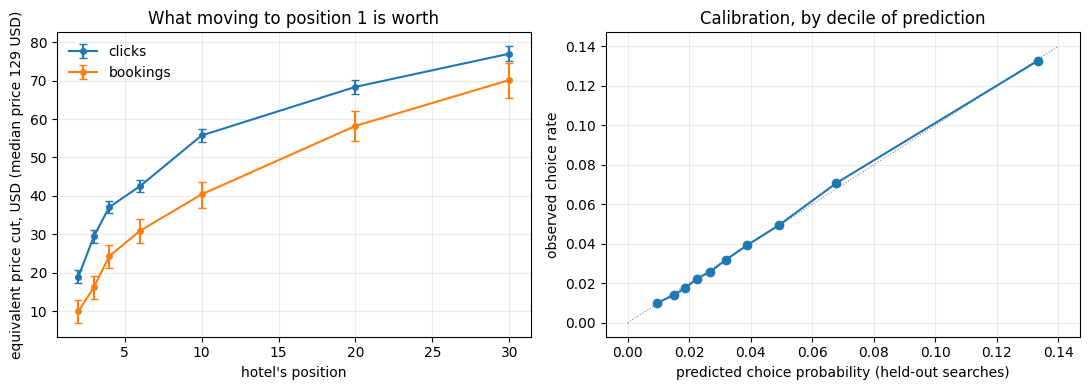

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for kind, colour in (("click", "#1f77b4"), ("booking", "#ff7f0e")):
    t = dollars[kind].loc[[i for i in dollars[kind].index if i.startswith("position")]]
    ks = [int(i.split()[-1]) for i in t.index]
    axes[0].errorbar(ks, t["usd"], yerr=[t["usd"] - t["usd_lo"], t["usd_hi"] - t["usd"]], marker="o", ms=4,
                     capsize=3, color=colour, label=f"{kind}s")
axes[0].set(xlabel="hotel's position", ylabel=f"equivalent price cut, USD (median price {MEDIAN_PRICE:.0f} USD)",
            title="What moving to position 1 is worth")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[1].plot([0, calib["pred"].max() * 1.05], [0, calib["pred"].max() * 1.05], color="grey", lw=0.8, ls=":")
axes[1].plot(calib["pred"], calib["obs"], marker="o", color="#1f77b4")
axes[1].set(xlabel="predicted choice probability (held-out searches)", ylabel="observed choice rate",
            title="Calibration, by decile of prediction")
axes[1].grid(alpha=0.25)
fig.tight_layout()

In [10]:
def fit_record(f: choice.ChoiceFit) -> dict:
    return {"names": f.names, "beta": [round(float(b), 6) for b in f.beta],
            "se": [round(float(s), 6) for s in f.se], "cov": [[float(c) for c in row] for row in f.cov],
            "loglik": round(f.loglik, 3), "loglik_null": round(f.loglik_null, 3),
            "mcfadden_r2": round(f.mcfadden_r2, 4), "searches": f.n_searches, "rows": f.rows,
            "converged": f.converged}


record = {
    "sample": {k: d.meta for k, d in data.items()},
    "median_price_usd": MEDIAN_PRICE,
    "price_coefficient": elasticity,
    "implied_pos1_over_pos30_odds_click": round(pos30_ratio, 3),
    "dollar_values": {k: {i: {c: float(v) for c, v in r.items()} for i, r in t.iterrows()} for k, t in dollars.items()},
    "price_identification": price_identification,
    "heterogeneity_upscale": heterogeneity,
    "holdout": holdout,
    "calibration": {int(i): {"pred": round(float(r.pred), 5), "obs": round(float(r.obs), 5)} for i, r in calib.iterrows()},
    "fits": {k: fit_record(f) for k, f in fits.items()},
}
out_path = write_metrics("03_choice_model", record, SOURCE)
print("wrote", out_path.relative_to(PROJECT_ROOT) if SOURCE == "real" else out_path.name)
if SOURCE == "real":
    fig.savefig(FIGURES_DIR / "03_choice_model.png", dpi=150, bbox_inches="tight")

wrote reports/metrics/03_choice_model.json
